# Non-linear static analysis with the arc-length methods

This example traces the snap-through of a hinged cylindrical roof under a central point load past its limit point, and compares the load-deflection path with the literature.

With load control, the Newton-Raphson method fails at a limit point, where the tangent stiffness matrix becomes singular and the load must decrease to follow the path. The arc-length methods add the load factor $\lambda$ to the unknowns, with a constraint on the length $\Delta s$ of each step along the path in the space of $(\boldsymbol{c}, \lambda)$:

$$
\boldsymbol{F}_{int}(\boldsymbol{c}) - \lambda \boldsymbol{F}_{ext} = \boldsymbol{0}, \qquad \frac{\Delta \boldsymbol{c}^\top \Delta \boldsymbol{c}}{\boldsymbol{u}_{ref}^\top \boldsymbol{u}_{ref}} + \psi^2 \Delta\lambda^2 = \Delta s^2 ,
$$

where $\boldsymbol{u}_{ref}$ is the linear solution for $\lambda = 1$, which makes $\Delta s$ independent of the units of the model, and $\psi$ is a constant. Riks's method iterates on the plane normal to the predictor of each step, while Crisfield's method keeps the spherical constraint. Both are implemented in [structsolve](https://github.com/saullocastro/structsolve), selected with `NL_method='arc_length_riks'` or `NL_method='arc_length_crisfield'` of `structsolve.Analysis`. The methods `calc_fext`, `calc_fint`, `calc_kC` and `calc_kG` of the `Shell` object are passed directly to `structsolve.Analysis`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from structsolve import Analysis
from panels.shell import Shell


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))

## The hinged roof of Sabir and Lock

The benchmark of Sabir and Lock (1972), as given by Sze et al. (2004), Section 3.8 and Fig. 9a, is a shallow cylindrical panel of radius $R = 2540$ mm and length $2L = 508$ mm along the axis, with free curved edges. Its straight edges are $R\theta$ apart, $\theta = 0.2$ rad, and hinged: $u = v = w = 0$ with the rotations free. The panel is isotropic, $E = 3102.75$ MPa, $\nu = 0.3$, $h = 12.7$ mm, and is loaded by a point force at its center. Units are N, mm and MPa. The model is `cylshell_clpt_donnell` with $12 \times 12$ terms and $24 \times 24$ integration points. A point load needs many terms: with $6 \times 6$ terms the panel is about 25% too stiff at the start of the path.

In [2]:
s = Shell(model='cylshell_clpt_donnell', a=508., b=2540.*0.2, r=2540.,
          stack=[0.], plyt=12.7, laminaprop=(3102.75, 0.3), m=12, n=12)
s.nx = 2*s.m
s.ny = 2*s.n
for edge in ('x1', 'x2', 'y1', 'y2'):
    for field in 'uvw':
        setattr(s, edge + field, 1.)
        setattr(s, edge + field + 'r', 1.)
for edge in ('y1', 'y2'):  # hinged straight edges
    for field in 'uvw':
        setattr(s, edge + field, 0.)

## Riks method

The reference load $P_{ref} = 4000$ N is larger than the limit load, so the analysis must pass the limit point and the snap-through before reaching $\lambda = 1$. `initialInc` is the first increment of $\lambda$. `maxArcLength` and `maxInc` limit the step, so that the path is sampled finely enough to show the limit point and the minimum load after it.

In [3]:
Pref = 4000.
s.add_point_load(s.a/2., s.b/2., 0., 0., -Pref, cte=False)

an = Analysis(s.calc_fext, s.calc_fint, s.calc_kC, s.calc_kG)
an.NL_method = 'arc_length_riks'
an.initialInc = 0.05
an.maxArcLength = 50.
an.maxInc = 0.02
increments, cs = an.static(NLgeom=True, silent=True)

lbds = np.asarray(increments)
wc = np.array([s.uvw(c=c, gridx=3, gridy=3)[1]['w'][1, 1] for c in cs])
for lbd, w in zip(lbds, wc):
    print('  load %7.1f N, center deflection %8.4f mm' % (lbd*Pref, w))

  load   199.6 N, center deflection  -0.4948 mm
  load   398.3 N, center deflection  -1.0148 mm
  load   596.0 N, center deflection  -1.5634 mm
  load   792.4 N, center deflection  -2.1448 mm
  load   987.5 N, center deflection  -2.7645 mm
  load  1180.7 N, center deflection  -3.4295 mm
  load  1371.5 N, center deflection  -4.1494 mm
  load  1559.0 N, center deflection  -4.9374 mm
  load  1741.3 N, center deflection  -5.8129 mm
  load  1914.8 N, center deflection  -6.8052 mm
  load  2071.4 N, center deflection  -7.9582 mm
  load  2189.7 N, center deflection  -9.3172 mm
  load  2226.0 N, center deflection -10.7913 mm
  load  2163.4 N, center deflection -12.0573 mm
  load  2039.8 N, center deflection -13.0264 mm
  load  1883.9 N, center deflection -13.7900 mm
  load  1708.1 N, center deflection -14.4265 mm
  load  1517.7 N, center deflection -14.9898 mm
  load  1316.1 N, center deflection -15.5232 mm
  load  1106.7 N, center deflection -16.0709 mm
  load   895.8 N, center deflection -16.

## Equilibrium and the path

Every converged step is in equilibrium: the residual $\boldsymbol{F}_{int} - \lambda \boldsymbol{F}_{ext}$ is small relative to the forces. The limit point is the last converged step before the first decrease of the load.

In [4]:
fext = s.calc_fext()
residuals = [np.linalg.norm(s.calc_fint(c=c) - lbd*fext)
             / max(np.linalg.norm(lbd*fext), np.linalg.norm(s.calc_fint(c=c)))
             for lbd, c in zip(lbds, cs)]
print('largest relative residual of the converged steps: %.2e'
      % max(residuals))
ilim = np.argmax(np.diff(lbds) < 0)
imin = ilim + np.argmin(lbds[ilim:])
print('limit point: %.1f N at w = %.3f mm; minimum after it: %.1f N at '
      'w = %.3f mm; final: %.1f N at w = %.3f mm'
      % (lbds[ilim]*Pref, wc[ilim], lbds[imin]*Pref, wc[imin],
         lbds[-1]*Pref, wc[-1]))

largest relative residual of the converged steps: 4.63e-09
limit point: 2226.0 N at w = -10.791 mm; minimum after it: 507.9 N at w = -19.648 mm; final: 4000.0 N at w = -30.250 mm


The load-deflection path against the path of Sze et al. (2004), Table 9a, p. 1565: their ABAQUS S4R results as $P/P_{max}$ against $-W_C$, with $P_{max} = 3000$ N (Fig. 9a, p. 1564), converted to $P = 3000\, P/P_{max}$ in N; the deflection is in mm in both.

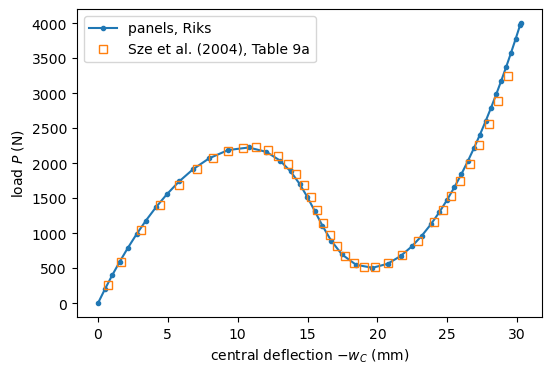

In [5]:
PMAX = 3000.
# Sze et al. (2004), Table 9a, p. 1565, 12.7 thick isotropic roof: (P/Pmax, -W_C)
SZE = np.array([
    (0.0877, 0.693), (0.1980, 1.638), (0.3473, 3.087), (0.4686, 4.477),
    (0.5647, 5.802), (0.6381, 7.057), (0.6908, 8.237), (0.7246, 9.339),
    (0.7412, 10.358), (0.7421, 11.293), (0.7286, 12.141), (0.7023, 12.903),
    (0.6649, 13.583), (0.6182, 14.188), (0.5643, 14.728), (0.5055, 15.217),
    (0.4442, 15.676), (0.3830, 16.125), (0.3245, 16.590), (0.2717, 17.094),
    (0.2272, 17.657), (0.1940, 18.299), (0.1750, 19.028), (0.1729, 19.852),
    (0.1905, 20.771), (0.2303, 21.780), (0.2950, 22.875), (0.3871, 24.049),
    (0.4443, 24.663), (0.5093, 25.293), (0.5826, 25.940), (0.6644, 26.601),
    (0.7551, 27.276), (0.8549, 27.964), (0.9643, 28.663), (1.0835, 29.374)])
sze_P, sze_W = PMAX*SZE[:, 0], SZE[:, 1]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(-np.r_[0, wc], np.r_[0, lbds]*Pref, 'o-', ms=3, label='panels, Riks')
ax.plot(sze_W, sze_P, 's', mfc='none', ms=6,
        label='Sze et al. (2004), Table 9a')
ax.set_xlabel('central deflection $-w_C$ (mm)')
ax.set_ylabel('load $P$ (N)')
ax.legend()
plt.show()

## Results

The central deflection grows monotonically along the path, so the load of `panels` at each deflection of Sze et al. is interpolated linearly between the converged steps, and compared at a few points of the path: on the rising branch, at the first maximum (the limit load, compared with the largest converged load, since the load is nearly constant around the limit point), at the minimum after the snap-through, and on the stiffening branch.

In [6]:
P_panels = np.interp(sze_W, -np.r_[0, wc], np.r_[0, lbds]*Pref)
isze_lim = np.argmax(np.diff(sze_P) < 0)
isze_min = isze_lim + np.argmin(sze_P[isze_lim:])
rows = [('limit load (N)', lbds[ilim]*Pref, sze_P[isze_lim],
         'Sze et al. (2004), Table 9a, $P/P_{max} = %.4f$' % SZE[isze_lim, 0]),
        ('minimum load after the limit point (N)', lbds[imin]*Pref,
         sze_P[isze_min],
         'Sze et al. (2004), Table 9a, $P/P_{max} = %.4f$' % SZE[isze_min, 0])]
for i in (0, 4, 15, 26, 34):
    rows.append(('$P$ at $-w_C = %.3f$ mm (N)' % sze_W[i], P_panels[i],
                 sze_P[i], 'Sze et al. (2004), Table 9a, $P/P_{max} = %.4f$'
                 % SZE[i, 0]))
results_table(rows)
diff = P_panels/sze_P - 1
print('relative difference of P over the 36 points: from %+.1f%% to %+.1f%%'
      % (100*diff.min(), 100*diff.max()))

| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| limit load (N) | 2226.04 | 2226.3 | -1.15e-04 | Sze et al. (2004), Table 9a, $P/P_{max} = 0.7421$ |
| minimum load after the limit point (N) | 507.945 | 518.7 | -2.07e-02 | Sze et al. (2004), Table 9a, $P/P_{max} = 0.1729$ |
| $P$ at $-w_C = 0.693$ mm (N) | 275.302 | 263.1 | +4.64e-02 | Sze et al. (2004), Table 9a, $P/P_{max} = 0.0877$ |
| $P$ at $-w_C = 5.802$ mm (N) | 1738.99 | 1694.1 | +2.65e-02 | Sze et al. (2004), Table 9a, $P/P_{max} = 0.5647$ |
| $P$ at $-w_C = 15.217$ mm (N) | 1431.81 | 1516.5 | -5.58e-02 | Sze et al. (2004), Table 9a, $P/P_{max} = 0.5055$ |
| $P$ at $-w_C = 22.875$ mm (N) | 901.054 | 885 | +1.81e-02 | Sze et al. (2004), Table 9a, $P/P_{max} = 0.2950$ |
| $P$ at $-w_C = 28.663$ mm (N) | 3072.32 | 2892.9 | +6.20e-02 | Sze et al. (2004), Table 9a, $P/P_{max} = 0.9643$ |

relative difference of P over the 36 points: from -5.6% to +6.7%


The limit load agrees with that of Sze et al. (2004) within 0.1%, and the minimum load after the snap-through within about 2%. Along the whole path the loads differ by up to about 7%: `panels` is stiffer on the rising branch, softer after the limit point and stiffer again on the final branch. Two sources of the difference are the number of terms, since the concentrated deformation under the point load converges slowly with the Ritz series (with $6 	imes 6$ terms the path is about 25% stiffer at the start), and the kinematics, Donnell's moderate-rotation shallow-shell theory here against the finite-rotation S4R shell elements of ABAQUS. The notebook [sze2004_hinged_roofs](sze2004_hinged_roofs.ipynb) compares the limit loads of all the roofs of Sze et al. (2004) with the shear-deformation models.

The same analysis runs with the Crisfield method by setting `an.NL_method = 'arc_length_crisfield'`.

## References

1. A. B. Sabir and A. C. Lock, "The application of finite elements to the large deflection geometrically nonlinear behaviour of cylindrical shells". In: C. A. Brebbia and H. Tottenham (eds), Variational Methods in Engineering, Southampton University Press, Southampton, UK, 1972, pp. 7/54-7/65 (as cited by Sze et al., 2004).
2. K. Y. Sze, X. H. Liu and S. H. Lo, "Popular benchmark problems for geometric nonlinear analysis of shells". Finite Elements in Analysis and Design, 40:1551-1569, 2004. https://doi.org/10.1016/j.finel.2003.11.001.